# IMDB Sentiment Analysis: RNN vs LSTM vs GRU vs BiLSTM

Binary sentiment classification of movie reviews with recurrent networks, compared against a **TF-IDF + Logistic Regression** baseline.

**Models:** Simple RNN, LSTM, GRU, Bidirectional LSTM (same Embedding → recurrent layer → Dropout → Dense architecture, same hyperparameters and callbacks).
**Dataset:** IMDB (Keras): 25,000 training and 25,000 test reviews, perfectly balanced.
**Metrics:** Accuracy, Precision, Recall, F1, training time, confusion matrices and learning curves.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

In [2]:

import re
import random
import tensorflow as tf
from tensorflow.keras.layers import Bidirectional
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

## 2. Configuration
All hyperparameters live here so the comparison between models is fair.

In [3]:
VOCAB_SIZE = 10_000
MAX_LENGTH = 200
EMBEDDING_DIM = 128
RNN_UNITS = 64
BATCH_SIZE = 64
EPOCHS = 15
RANDOM_STATE = 42

## 3. Reproducibility
Fixed random seeds for Python, NumPy and TensorFlow.

In [4]:

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

## 4. Load the dataset
Reviews come pre-encoded as word IDs; only the 10,000 most frequent words are kept.

In [5]:
(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=VOCAB_SIZE)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 25000
Testing samples: 25000


## 5. Explore the data
A first look at an encoded review and the class balance.

In [6]:
print("First encoded review:")
print(X_train[0])

print("\nLabel:")
print(y_train[0])

First encoded review:
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32]

Label:
1


In [7]:
print("Number of positive reviews:", np.sum(y_train == 1))
print("Number of negative reviews:", np.sum(y_train == 0))

Number of positive reviews: 12500
Number of negative reviews: 12500


## 6. Review length distribution
Used to choose a reasonable `MAX_LENGTH` for padding.

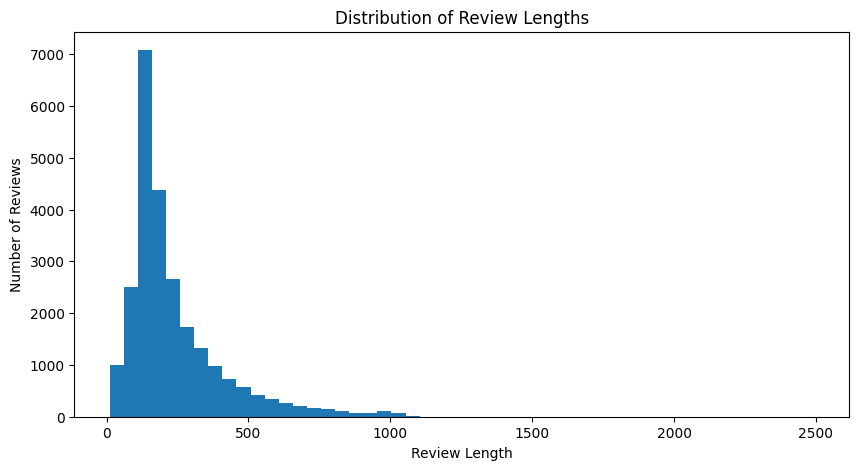

In [8]:
train_lengths = [len(x) for x in X_train]

plt.figure(figsize=(10, 5))
plt.hist(train_lengths, bins=50)
plt.xlabel("Review Length")
plt.ylabel("Number of Reviews")
plt.title("Distribution of Review Lengths")
plt.show()

## 7. Decode reviews back to text
Keras reserves indices 0 (`<PAD>`), 1 (`<START>`) and 2 (`<UNK>`), so word indices are shifted by +3.

In [9]:
word_index = imdb.get_word_index()

reverse_word_index = {
    value + 3: key
    for key, value in word_index.items()
}
reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<UNK>"

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [10]:
def decode_review(encoded_review):
    return " ".join(
        reverse_word_index.get(i, "?")
        for i in encoded_review
    )

print(decode_review(X_train[0]))

<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also <UNK> to the two little boy's that played the <UNK> of norman and paul they were just brilliant children are often left out of the <UNK> list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for wha

## 8. Padding
Every review is padded/truncated to 200 tokens with **`pre`** padding and truncating.

> An earlier run used `post` padding, and Simple RNN and GRU stayed at about 51% accuracy (chance level): the recurrent state had to cross many padding tokens before the prediction, and truncating from the end removed the part of the review that usually holds the verdict.

In [11]:
X_train_pad = pad_sequences(
    X_train,
    maxlen=MAX_LENGTH,
    padding="pre",
    truncating="pre",
)
X_test_pad = pad_sequences(
    X_test,
    maxlen=MAX_LENGTH,
    padding="pre",
    truncating="pre",
)

In [12]:
print("Before padding:", len(X_train[0]))
print("After padding:", len(X_train_pad[0]))
print(X_train_pad.shape)
print(X_test_pad.shape)

Before padding: 218
After padding: 200
(25000, 200)
(25000, 200)


## 9. Simple RNN
Architecture: Embedding → SimpleRNN → Dropout → Dense (sigmoid).

In [13]:
def build_rnn_model():
    model = Sequential([
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=EMBEDDING_DIM,
        ),
        SimpleRNN(RNN_UNITS),
        Dropout(0.5),
        Dense(1, activation="sigmoid"),
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [14]:
rnn_model = build_rnn_model()
rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### Training
EarlyStopping on `val_loss` (patience 5, best weights restored); a fresh callback is created for every model.

In [15]:
def make_early_stopping():
    return EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
    )

start_time = time.time()
rnn_history = rnn_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.2,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[make_early_stopping()],
    verbose=1,
)
rnn_training_time = time.time() - start_time
print(f"Training time: {rnn_training_time:.2f} seconds")

Epoch 1/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 34s 94ms/step - accuracy: 0.6511 - loss: 0.6177 - val_accuracy: 0.7398 - val_loss: 0.5167
Epoch 2/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 93ms/step - accuracy: 0.8217 - loss: 0.4088 - val_accuracy: 0.8016 - val_loss: 0.4424
Epoch 3/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 28s 90ms/step - accuracy: 0.8439 - loss: 0.3605 - val_accuracy: 0.6804 - val_loss: 0.6276
Epoch 4/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 28s 90ms/step - accuracy: 0.9082 - loss: 0.2343 - val_accuracy: 0.7526 - val_loss: 0.6021
Epoch 5/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 28s 90ms/step - accuracy: 0.9712 - loss: 0.0899 - val_accuracy: 0.7682 - val_loss: 0.7230
Epoch 6/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 94ms/step - accuracy: 0.9842 - loss: 0.0533 - val_accuracy: 0.7612 - val_loss: 0.8030
Epoch 7/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 92ms/step - accuracy: 0.9891 - loss: 0.0343 - val_accuracy: 0.7576 - val_loss: 0.8921
Training time: 205.73 seconds


### Evaluation (test set)

In [16]:
rnn_probabilities = rnn_model.predict(X_test_pad)
rnn_predictions = (rnn_probabilities >= 0.5).astype(int).flatten()

rnn_accuracy  = accuracy_score(y_test, rnn_predictions)
rnn_precision = precision_score(y_test, rnn_predictions)
rnn_recall    = recall_score(y_test, rnn_predictions)
rnn_f1        = f1_score(y_test, rnn_predictions)

print("RNN Results")
print("-" * 30)
print("Accuracy :", rnn_accuracy)
print("Precision:", rnn_precision)
print("Recall   :", rnn_recall)
print("F1 Score :", rnn_f1)

782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step
RNN Results
------------------------------
Accuracy : 0.80484
Precision: 0.7855804541707262
Recall   : 0.83856
F1 Score : 0.8112061293193514


In [17]:
print(
    classification_report(
        y_test,
        rnn_predictions,
        target_names=["Negative", "Positive"],
    )
)

              precision    recall  f1-score   support

    Negative       0.83      0.77      0.80     12500
    Positive       0.79      0.84      0.81     12500

    accuracy                           0.80     25000
   macro avg       0.81      0.80      0.80     25000
weighted avg       0.81      0.80      0.80     25000



### Confusion matrix and learning curves

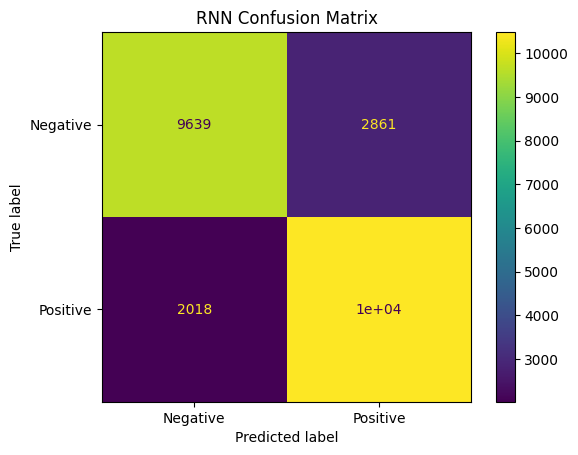

In [18]:
cm = confusion_matrix(y_test, rnn_predictions)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"],
)
disp.plot()
plt.title("RNN Confusion Matrix")
plt.show()

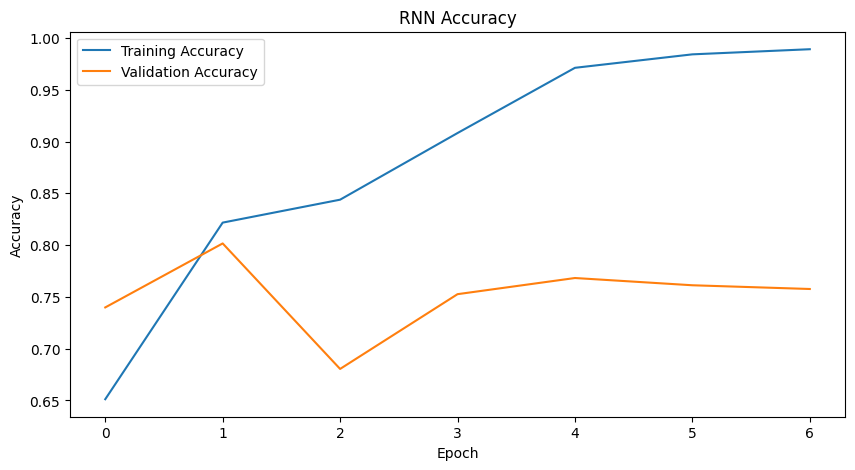

In [19]:
plt.figure(figsize=(10, 5))
plt.plot(rnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(rnn_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("RNN Accuracy")
plt.legend()
plt.show()

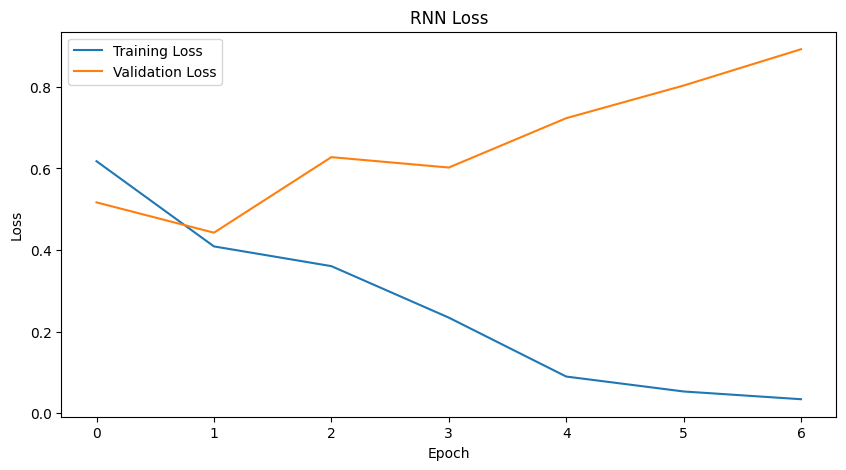

In [20]:
plt.figure(figsize=(10, 5))
plt.plot(rnn_history.history["loss"], label="Training Loss")
plt.plot(rnn_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("RNN Loss")
plt.legend()
plt.show()

## 10. LSTM
Same architecture with an LSTM layer.

In [21]:
def build_lstm_model():
    model = Sequential([
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=EMBEDDING_DIM,
        ),
        LSTM(RNN_UNITS),
        Dropout(0.5),
        Dense(1, activation="sigmoid"),
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [22]:
lstm_model = build_lstm_model()
lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [23]:
start_time = time.time()
lstm_history = lstm_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.2,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[make_early_stopping()],
    verbose=1,
)
lstm_training_time = time.time() - start_time
print(f"Training time: {lstm_training_time:.2f} seconds")

Epoch 1/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 79s 245ms/step - accuracy: 0.7474 - loss: 0.4917 - val_accuracy: 0.8632 - val_loss: 0.3306
Epoch 2/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 245ms/step - accuracy: 0.8959 - loss: 0.2663 - val_accuracy: 0.8712 - val_loss: 0.3263
Epoch 3/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 76s 244ms/step - accuracy: 0.9198 - loss: 0.2178 - val_accuracy: 0.8270 - val_loss: 0.4061
Epoch 4/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 78s 249ms/step - accuracy: 0.9340 - loss: 0.1818 - val_accuracy: 0.8716 - val_loss: 0.3586
Epoch 5/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 79s 253ms/step - accuracy: 0.9398 - loss: 0.1675 - val_accuracy: 0.8548 - val_loss: 0.3768
Epoch 6/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 79s 253ms/step - accuracy: 0.9553 - loss: 0.1285 - val_accuracy: 0.8594 - val_loss: 0.4298
Epoch 7/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 77s 248ms/step - accuracy: 0.9534 - loss: 0.1306 - val_accuracy: 0.8474 - val_loss: 0.4868
Training time: 551.17 seconds


In [24]:
lstm_probabilities = lstm_model.predict(X_test_pad)
lstm_predictions = (lstm_probabilities >= 0.5).astype(int).flatten()

lstm_accuracy  = accuracy_score(y_test, lstm_predictions)
lstm_precision = precision_score(y_test, lstm_predictions)
lstm_recall    = recall_score(y_test, lstm_predictions)
lstm_f1        = f1_score(y_test, lstm_predictions)

print("LSTM Results")
print("-" * 30)
print("Accuracy :", lstm_accuracy)
print("Precision:", lstm_precision)
print("Recall   :", lstm_recall)
print("F1 Score :", lstm_f1)

782/782 ━━━━━━━━━━━━━━━━━━━━ 24s 30ms/step
LSTM Results
------------------------------
Accuracy : 0.8662
Precision: 0.8535568085270719
Recall   : 0.88408
F1 Score : 0.8685503202735096


In [25]:
print(
    classification_report(
        y_test,
        lstm_predictions,
        target_names=["Negative", "Positive"],
    )
)

              precision    recall  f1-score   support

    Negative       0.88      0.85      0.86     12500
    Positive       0.85      0.88      0.87     12500

    accuracy                           0.87     25000
   macro avg       0.87      0.87      0.87     25000
weighted avg       0.87      0.87      0.87     25000



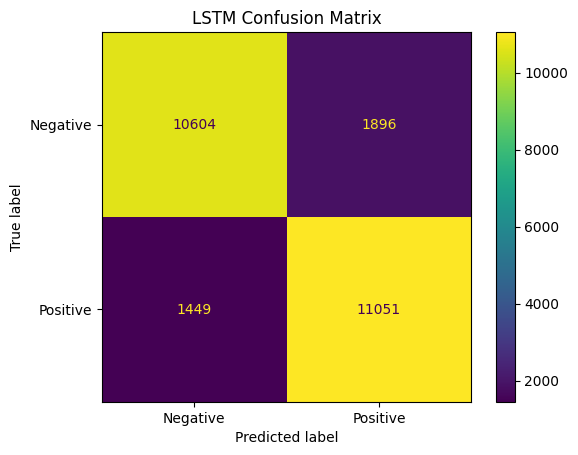

In [26]:
cm = confusion_matrix(y_test, lstm_predictions)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"],
)
disp.plot()
plt.title("LSTM Confusion Matrix")
plt.show()

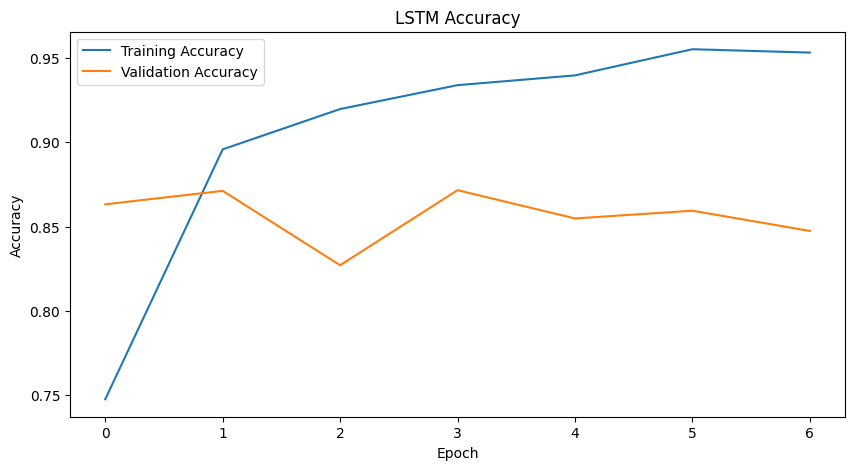

In [27]:
plt.figure(figsize=(10, 5))
plt.plot(lstm_history.history["accuracy"], label="Training Accuracy")
plt.plot(lstm_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Accuracy")
plt.legend()
plt.show()

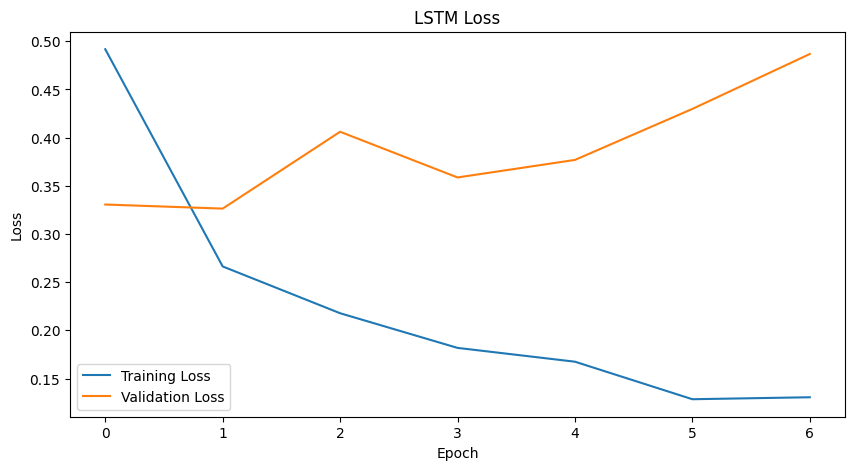

In [28]:
plt.figure(figsize=(10, 5))
plt.plot(lstm_history.history["loss"], label="Training Loss")
plt.plot(lstm_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Loss")
plt.legend()
plt.show()

## 11. GRU
Same architecture with a GRU layer.

In [29]:
def build_gru_model():
    model = Sequential([
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=EMBEDDING_DIM,
        ),
        GRU(RNN_UNITS),
        Dropout(0.5),
        Dense(1, activation="sigmoid"),
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [30]:
gru_model = build_gru_model()
gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [31]:
start_time = time.time()
gru_history = gru_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.2,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[make_early_stopping()],
    verbose=1,
)
gru_training_time = time.time() - start_time
print(f"Training time: {gru_training_time:.2f} seconds")

Epoch 1/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 96s 300ms/step - accuracy: 0.7321 - loss: 0.5151 - val_accuracy: 0.8516 - val_loss: 0.3528
Epoch 2/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 84s 270ms/step - accuracy: 0.8946 - loss: 0.2701 - val_accuracy: 0.8496 - val_loss: 0.3567
Epoch 3/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 141s 268ms/step - accuracy: 0.9250 - loss: 0.2008 - val_accuracy: 0.8500 - val_loss: 0.3667
Epoch 4/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 142s 270ms/step - accuracy: 0.9434 - loss: 0.1561 - val_accuracy: 0.8536 - val_loss: 0.4108
Epoch 5/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 84s 269ms/step - accuracy: 0.9609 - loss: 0.1122 - val_accuracy: 0.8596 - val_loss: 0.4805
Epoch 6/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 83s 265ms/step - accuracy: 0.9755 - loss: 0.0713 - val_accuracy: 0.8602 - val_loss: 0.5253
Training time: 631.99 seconds


In [32]:
gru_probabilities = gru_model.predict(X_test_pad)
gru_predictions = (gru_probabilities >= 0.5).astype(int).flatten()

gru_accuracy  = accuracy_score(y_test, gru_predictions)
gru_precision = precision_score(y_test, gru_predictions)
gru_recall    = recall_score(y_test, gru_predictions)
gru_f1        = f1_score(y_test, gru_predictions)

print("GRU Results")
print("-" * 30)
print("Accuracy :", gru_accuracy)
print("Precision:", gru_precision)
print("Recall   :", gru_recall)
print("F1 Score :", gru_f1)

782/782 ━━━━━━━━━━━━━━━━━━━━ 25s 32ms/step
GRU Results
------------------------------
Accuracy : 0.84644
Precision: 0.8252835574250732
Recall   : 0.87896
F1 Score : 0.85127648859102


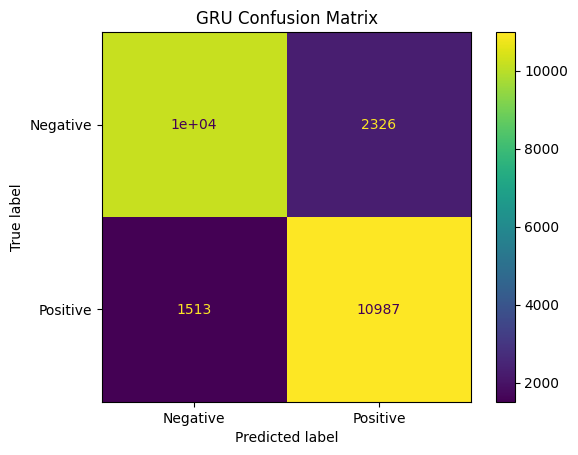

In [33]:
cm = confusion_matrix(y_test, gru_predictions)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"],
)
disp.plot()
plt.title("GRU Confusion Matrix")
plt.show()

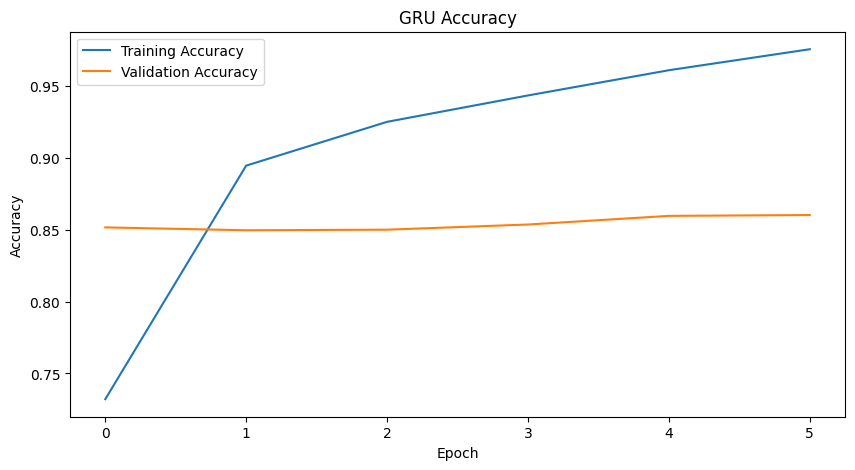

In [34]:
plt.figure(figsize=(10, 5))
plt.plot(gru_history.history["accuracy"], label="Training Accuracy")
plt.plot(gru_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("GRU Accuracy")
plt.legend()
plt.show()

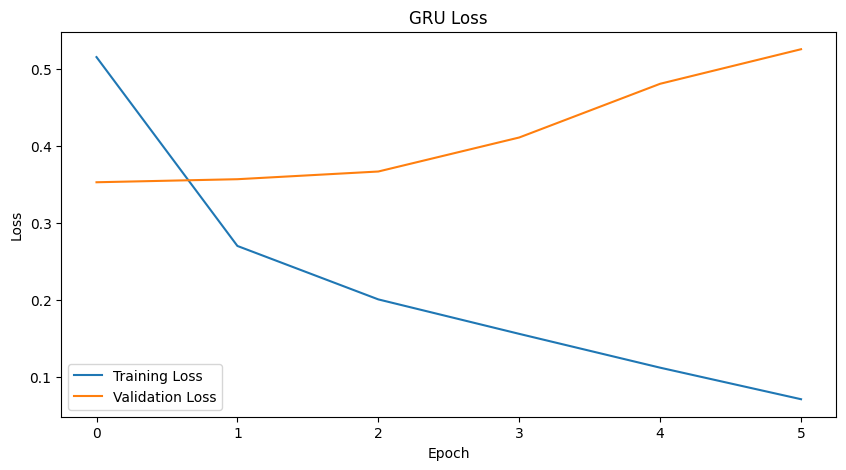

In [35]:
plt.figure(figsize=(10, 5))
plt.plot(gru_history.history["loss"], label="Training Loss")
plt.plot(gru_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GRU Loss")
plt.legend()
plt.show()

## 12. Baseline: TF-IDF + Logistic Regression
A classical model on the same data (word IDs treated as tokens, unigrams + bigrams). If a deep model cannot beat this, its extra cost is hard to justify.

In [36]:
def ids_to_text(sequences):
    return [" ".join(map(str, s)) for s in sequences]

start_time = time.time()
tfidf = TfidfVectorizer(token_pattern=r"\S+", ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(ids_to_text(X_train))
X_test_tfidf = tfidf.transform(ids_to_text(X_test))

baseline = LogisticRegression(max_iter=2000, C=4, random_state=RANDOM_STATE)
baseline.fit(X_train_tfidf, y_train)
baseline_training_time = time.time() - start_time

baseline_predictions = baseline.predict(X_test_tfidf)
baseline_accuracy  = accuracy_score(y_test, baseline_predictions)
baseline_precision = precision_score(y_test, baseline_predictions)
baseline_recall    = recall_score(y_test, baseline_predictions)
baseline_f1        = f1_score(y_test, baseline_predictions)

print("TF-IDF + Logistic Regression")
print("-" * 30)
print("Accuracy :", baseline_accuracy)
print("Precision:", baseline_precision)
print("Recall   :", baseline_recall)
print("F1 Score :", baseline_f1)
print(f"Training time: {baseline_training_time:.2f} seconds")

TF-IDF + Logistic Regression
------------------------------
Accuracy : 0.90796
Precision: 0.9053334393132502
Recall   : 0.9112
F1 Score : 0.908257246521271
Training time: 36.83 seconds


## 13. Bidirectional LSTM
The LSTM reads each review forwards and backwards.

In [37]:
def build_bilstm_model():
    model = Sequential([
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=EMBEDDING_DIM,
        ),
        Bidirectional(LSTM(RNN_UNITS)),
        Dropout(0.5),
        Dense(1, activation="sigmoid"),
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model

bilstm_model = build_bilstm_model()

start_time = time.time()
bilstm_history = bilstm_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.2,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[make_early_stopping()],
    verbose=1,
)
bilstm_training_time = time.time() - start_time
print(f"Training time: {bilstm_training_time:.2f} seconds")

Epoch 1/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 150s 470ms/step - accuracy: 0.7869 - loss: 0.4459 - val_accuracy: 0.8692 - val_loss: 0.3188
Epoch 2/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 136s 435ms/step - accuracy: 0.9006 - loss: 0.2602 - val_accuracy: 0.8326 - val_loss: 0.3907
Epoch 3/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 143s 438ms/step - accuracy: 0.9125 - loss: 0.2295 - val_accuracy: 0.8394 - val_loss: 0.3570
Epoch 4/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 143s 440ms/step - accuracy: 0.9268 - loss: 0.1972 - val_accuracy: 0.8378 - val_loss: 0.3942
Epoch 5/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 142s 443ms/step - accuracy: 0.9557 - loss: 0.1302 - val_accuracy: 0.8562 - val_loss: 0.4083
Epoch 6/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 136s 434ms/step - accuracy: 0.9564 - loss: 0.1267 - val_accuracy: 0.8520 - val_loss: 0.4555
Training time: 850.66 seconds


In [38]:
bilstm_probabilities = bilstm_model.predict(X_test_pad)
bilstm_predictions = (bilstm_probabilities >= 0.5).astype(int).flatten()

bilstm_accuracy  = accuracy_score(y_test, bilstm_predictions)
bilstm_precision = precision_score(y_test, bilstm_predictions)
bilstm_recall    = recall_score(y_test, bilstm_predictions)
bilstm_f1        = f1_score(y_test, bilstm_predictions)

print("BiLSTM Results")
print("-" * 30)
print("Accuracy :", bilstm_accuracy)
print("Precision:", bilstm_precision)
print("Recall   :", bilstm_recall)
print("F1 Score :", bilstm_f1)
print()
print(classification_report(y_test, bilstm_predictions, target_names=["Negative", "Positive"]))

782/782 ━━━━━━━━━━━━━━━━━━━━ 41s 52ms/step
BiLSTM Results
------------------------------
Accuracy : 0.86296
Precision: 0.8786513102987815
Recall   : 0.84224
F1 Score : 0.8600604525774038

              precision    recall  f1-score   support

    Negative       0.85      0.88      0.87     12500
    Positive       0.88      0.84      0.86     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.86     25000
weighted avg       0.86      0.86      0.86     25000



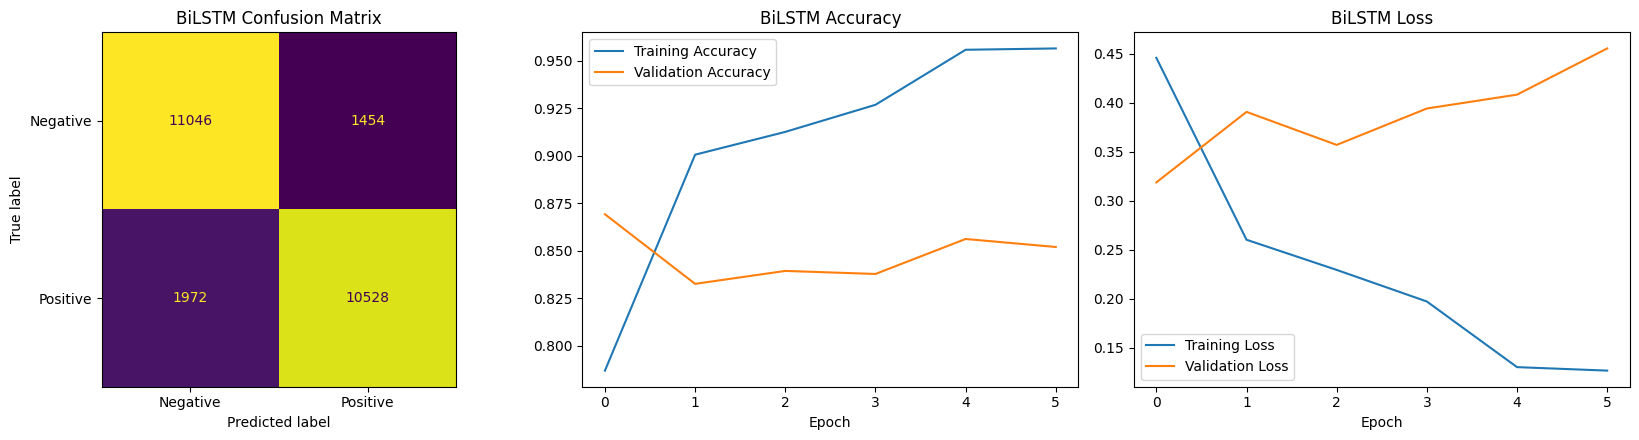

In [49]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

ConfusionMatrixDisplay(confusion_matrix(y_test, bilstm_predictions),
                       display_labels=["Negative", "Positive"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title("BiLSTM Confusion Matrix")

ax[1].plot(bilstm_history.history["accuracy"], label="Training Accuracy")
ax[1].plot(bilstm_history.history["val_accuracy"], label="Validation Accuracy")
ax[1].set_title("BiLSTM Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()

ax[2].plot(bilstm_history.history["loss"], label="Training Loss")
ax[2].plot(bilstm_history.history["val_loss"], label="Validation Loss")
ax[2].set_title("BiLSTM Loss"); ax[2].set_xlabel("Epoch"); ax[2].legend()

plt.tight_layout(); plt.show()

## 14. Compare all models

In [40]:
results = pd.DataFrame({
    "Model": ["Simple RNN", "LSTM", "GRU", "BiLSTM", "TF-IDF + LogReg"],   # CHANGED: 5 models

    "Accuracy":  [rnn_accuracy,  lstm_accuracy,  gru_accuracy,  bilstm_accuracy,  baseline_accuracy],
    "Precision": [rnn_precision, lstm_precision, gru_precision, bilstm_precision, baseline_precision],
    "Recall":    [rnn_recall,    lstm_recall,    gru_recall,    bilstm_recall,    baseline_recall],
    "F1 Score":  [rnn_f1,        lstm_f1,        gru_f1,        bilstm_f1,        baseline_f1],

    "Training Time (sec)": [
        rnn_training_time,
        lstm_training_time,
        gru_training_time,
        bilstm_training_time,
        baseline_training_time,
    ],
})
results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,Training Time (sec)
0,Simple RNN,0.8048,0.7856,0.8386,0.8112,205.7307
1,LSTM,0.8662,0.8536,0.8841,0.8686,551.1690
2,GRU,0.8464,0.8253,0.8790,0.8513,631.9871
3,BiLSTM,0.8630,0.8787,0.8422,0.8601,850.6567
4,TF-IDF + LogReg,0.9080,0.9053,0.9112,0.9083,36.8273


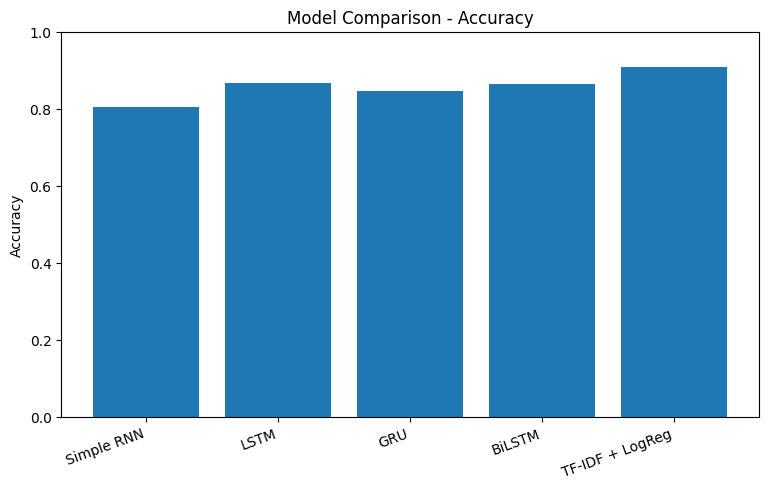

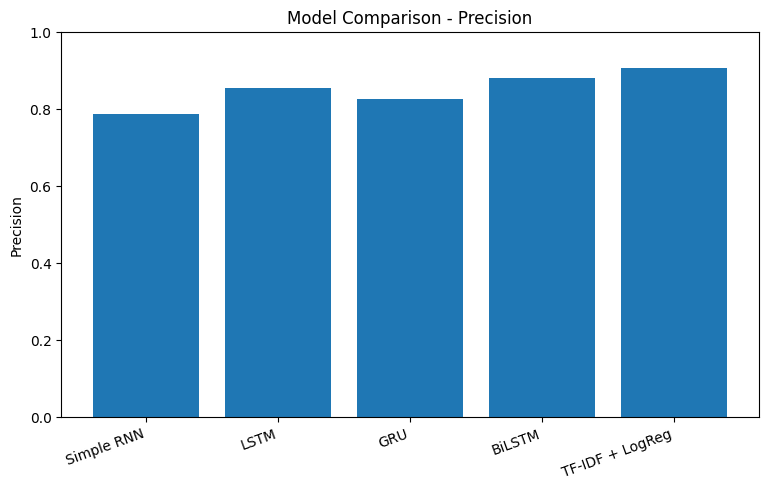

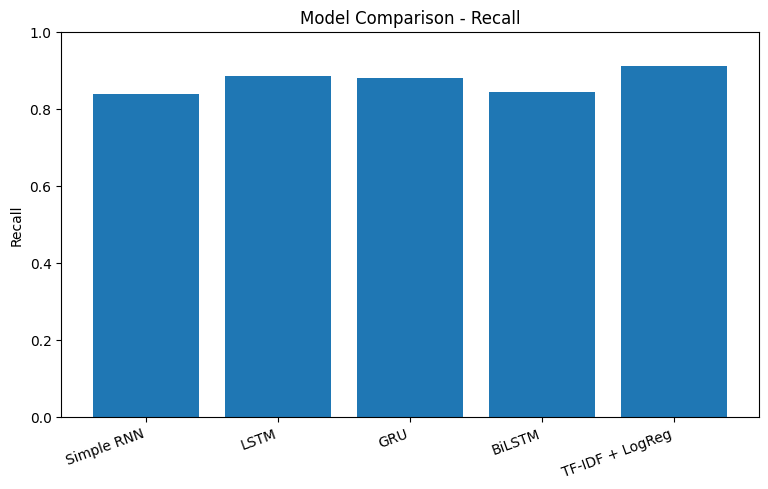

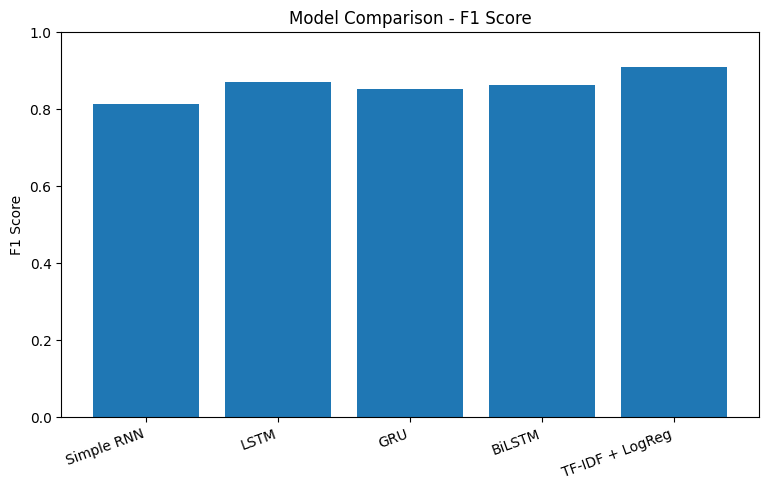

In [41]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

for metric in metrics:
    plt.figure(figsize=(9, 5))
    plt.bar(results["Model"], results[metric])
    plt.ylabel(metric)
    plt.title(f"Model Comparison - {metric}")
    plt.ylim(0, 1)
    plt.xticks(rotation=20, ha='right')
    plt.show()

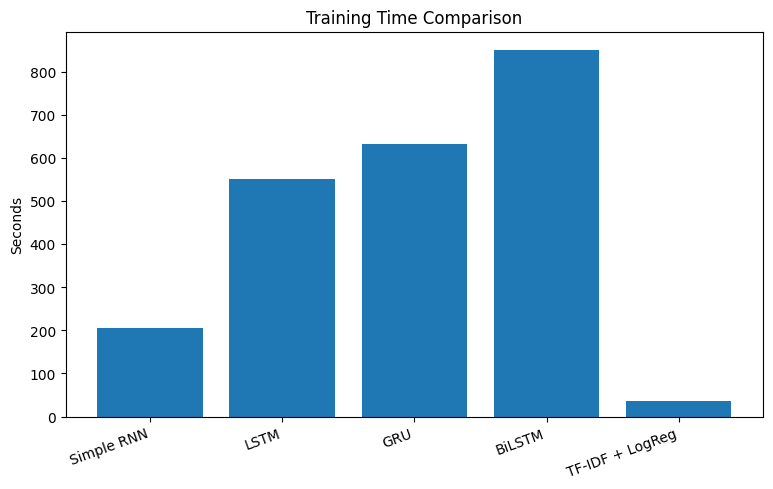

In [42]:
plt.figure(figsize=(9, 5))
plt.bar(results["Model"], results["Training Time (sec)"])
plt.ylabel("Seconds")
plt.title("Training Time Comparison")
plt.xticks(rotation=20, ha='right')
plt.show()

### Observations

- **The TF-IDF + Logistic Regression baseline is the best model** (accuracy 0.908, F1 0.908) and trains in about 37 seconds. Every deep model scored lower; the best, LSTM, reached 0.866 accuracy and 0.869 F1.
- Among the deep models the ranking by F1 is LSTM (0.869), BiLSTM (0.860), GRU (0.851) and Simple RNN (0.811). The gaps between LSTM, BiLSTM and GRU are small and come from a single run, so they should not be over-interpreted.
- **All deep models overfit quickly:** the best validation loss appeared in epoch 1 or 2 while training accuracy kept climbing to 95-99%. EarlyStopping restored the best weights, but the models memorize the training reviews.
- **Training times are not directly comparable:** each model stopped after a different number of epochs and Colab speed varied (GRU was slower than LSTM here). Per-epoch cost, roughly 29 s for Simple RNN, 78 s for LSTM and 140 s for BiLSTM, is a fairer comparison.
- **Plausible reasons the baseline wins** (not tested here): bigrams capture phrases such as "not good", it reads the whole review while the networks see only 200 tokens, and the networks learn embeddings from scratch on just 20,000 reviews.

## 15. Test on new reviews
New text is encoded exactly like the training data: `<START>` first, IDs shifted by +3, unknown or out-of-vocabulary words mapped to `<UNK>`.

In [43]:
def encode_new_review(text):
    words = re.findall(r"[a-z']+", text.lower())
    encoded = [1]
    for word in words:
        idx = word_index.get(word)
        if idx is None or idx + 3 >= VOCAB_SIZE:
            encoded.append(2)
        else:
            encoded.append(idx + 3)

    return pad_sequences(
        [encoded],
        maxlen=MAX_LENGTH,
        padding="pre",
        truncating="pre",
    )

In [44]:
def predict_sentiment(model, text):
    encoded_text = encode_new_review(text)
    probability = model.predict(encoded_text, verbose=0)[0][0]

    if probability >= 0.5:
        sentiment = "Positive"
        confidence = probability
    else:
        sentiment = "Negative"
        confidence = 1 - probability

    return sentiment, confidence

In [46]:
reviews = [
    "This movie was absolutely amazing and I loved it",
    "This movie was terrible and boring",
    "I really enjoyed this film",
    "The movie was not good and I hated it",
    "I would not recommend this film, a complete waste of time",
]
for review in reviews:
    print("\nReview:", review)
    for name, model in [
        ("RNN", rnn_model),
        ("LSTM", lstm_model),
        ("GRU", gru_model),
        ("BiLSTM", bilstm_model),
    ]:
        sentiment, confidence = predict_sentiment(model, review)
        print(f"{name}: {sentiment} ({confidence:.2%})")


Review: This movie was absolutely amazing and I loved it
RNN: Positive (97.30%)
LSTM: Positive (96.24%)
GRU: Positive (97.76%)
BiLSTM: Positive (96.01%)

Review: This movie was terrible and boring
RNN: Negative (64.77%)
LSTM: Negative (93.85%)
GRU: Negative (66.65%)
BiLSTM: Negative (66.77%)

Review: I really enjoyed this film
RNN: Positive (93.43%)
LSTM: Positive (75.46%)
GRU: Positive (95.78%)
BiLSTM: Positive (92.32%)

Review: The movie was not good and I hated it
RNN: Positive (71.74%)
LSTM: Negative (59.47%)
GRU: Positive (90.38%)
BiLSTM: Positive (72.10%)

Review: I would not recommend this film, a complete waste of time
RNN: Negative (89.26%)
LSTM: Negative (96.23%)
GRU: Negative (70.54%)
BiLSTM: Negative (85.03%)


## 16. Error analysis
Reviews the best deep model (LSTM) got wrong.

In [47]:
test_texts = [
    decode_review(X_test[i])
    for i in range(len(X_test))
]

deep_predictions = {
    "Simple RNN": rnn_predictions, "LSTM": lstm_predictions,
    "GRU": gru_predictions, "BiLSTM": bilstm_predictions,
}
best_deep = max(deep_predictions, key=lambda n: f1_score(y_test, deep_predictions[n]))
best_preds = deep_predictions[best_deep]
print("Best deep model:", best_deep)

error_indices = np.where(best_preds != y_test)[0]
print("Number of errors:", len(error_indices))

Best deep model: LSTM
Number of errors: 3345


In [48]:
for i in error_indices[:10]:
    print("=" * 80)
    print("Review:")
    print(test_texts[i][:1000])

    print("\nActual:",    "Positive" if y_test[i] == 1 else "Negative")
    print("Predicted:", "Positive" if best_preds[i] == 1 else "Negative")

Review:
<START> i generally love this type of movie however this time i found myself wanting to kick the screen since i can't do that i will just complain about it this was absolutely idiotic the things that happen with the dead kids are very cool but the alive people are absolute idiots i am a grown man pretty big and i can defend myself well however i would not do half the stuff the little girl does in this movie also the mother in this movie is reckless with her children to the point of neglect i wish i wasn't so angry about her and her actions because i would have otherwise enjoyed the flick what a number she was take my advise and fast forward through everything you see her do until the end also is anyone else getting sick of watching movies that are filmed so dark anymore one can hardly see what is being filmed as an audience we are <UNK> involved with the actions on the screen so then why the hell can't we have night vision

Actual: Negative
Predicted: Positive
Review:
<START> h

## 17. Conclusions

- A strong classical baseline beat all four recurrent models on this task, so deep learning was not worth its cost here. It is essential to run a baseline before claiming a neural model is better.
- **Preprocessing mattered more than architecture:** with `post` padding, Simple RNN and GRU stayed at chance level; with `pre` padding and a longer patience they trained properly.
- **Negation is a weak spot.** "The movie was not good and I hated it" was classified as positive by Simple RNN, GRU and BiLSTM; only the LSTM got it right, with about 59% confidence.
- The best deep model (LSTM) made 3,345 errors on 25,000 test reviews (13.4%). The reviews it misses are mostly long, mix praise with criticism, or contain many `<UNK>` tokens.
- **Next steps:** stronger regularization (embedding dropout, recurrent dropout, smaller embedding), pretrained embeddings such as GloVe, longer sequences, or fine-tuning a transformer like DistilBERT.